# Make the train Model

In [826]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torch.utils.data import TensorDataset
from torch.utils.data import DataLoader
import torch.nn as nn


In [827]:
# raw data
months = list(range(25))

# Length-for-age (cm) - girls median (50th percentile)
length = [
    49.9, 54.7, 58.4, 61.4, 63.9, 65.9, 67.6, 69.2, 70.6, 72.0, 73.3, 74.5,
    75.7, 76.9, 78.0, 79.2, 80.2, 81.2, 82.3, 83.2, 84.2, 85.1, 86.0, 86.9, 87.8
]

# Weight-for-age (kg) - girls median (50th percentile)
weight = [
    3.3, 4.5, 5.6, 6.4, 7.0, 7.5, 7.9, 8.3, 8.6, 8.9, 9.2, 9.4,
    9.6, 9.9, 10.1, 10.3, 10.5, 10.7, 10.9, 11.1, 11.3, 11.5, 11.7, 11.9, 12.0
]

# Head circumference-for-age (cm) - girls median (50th percentile)
head_circ = [
    34.5, 37.3, 39.1, 40.5, 41.6, 42.6, 43.3, 43.9, 44.4, 44.8, 45.2, 45.5,
    45.8, 46.1, 46.3, 46.6, 46.8, 47.0, 47.2, 47.4, 47.5, 47.7, 47.8, 48.0, 48.1
]


In [828]:
# stack(combine) the data
month_a = np.array(months)
length_a = np.array(length)
weight_a = np.array(weight)
head_a = np.array(head_circ)

data = np.stack((head_a, length_a, month_a), axis=-1)
input = np.array(data, dtype='float32')

# print(f"input \n{inputs}")

target = np.array(weight_a, dtype='float32')
# print(f"target \n{target}")

inputs = torch.from_numpy(input)
targets = torch.from_numpy(target)

targets = targets.view(-1, 1)


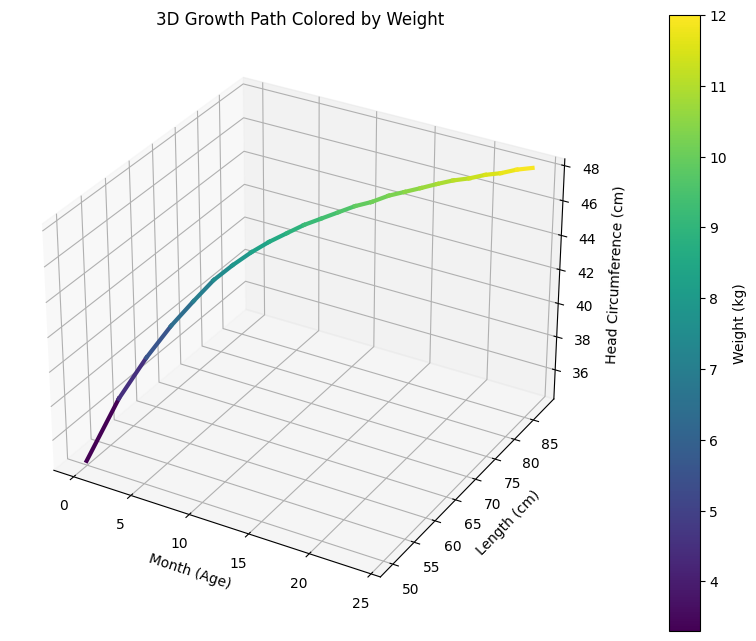

In [847]:
# Convert tensors to NumPy arrays
head_circs = inputs[:, 0].numpy()
lengths = inputs[:, 1].numpy()
months = inputs[:, 2].numpy()
weights = targets.numpy()

# Create a 3D plot
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Get a colormap and normalize the weights for coloring
cmap = plt.cm.viridis
norm = plt.Normalize(weights.min(), weights.max())

# Plot each segment of the line and color it by weight
for i in range(len(months) - 1):
    ax.plot(
        months[i:i+2],
        lengths[i:i+2],
        head_circs[i:i+2],
        color=cmap(norm(weights[i])),
        linewidth=3
    )

# Set labels for each axis
ax.set_xlabel('Month (Age)')
ax.set_ylabel('Length (cm)')
ax.set_zlabel('Head Circumference (cm)')
ax.set_title('3D IDEAL Growth Path Colored by Weight')

# Add a color bar
scalar_mappable = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
scalar_mappable.set_array(weights)
cbar = fig.colorbar(scalar_mappable, ax=ax, pad=0.1)
cbar.set_label('Weight (kg)')

plt.show()

In [830]:
# Normalize
mean = targets.mean()
std = targets.std()

targets = (targets - mean) / std

In [831]:
# set the data set and data loader
train_ds = TensorDataset(inputs, targets)
batch_size = 5
train_dl = DataLoader(train_ds, batch_size, shuffle=True)

In [881]:
# preview the data in the loop for the one already data loader + shuffle (which show 5 only)
for xb, yb in train_dl:
    print(xb)
    print(yb)
    break

tensor([[45.2000, 73.3000, 10.0000],
        [47.7000, 85.1000, 21.0000],
        [48.1000, 87.8000, 24.0000],
        [46.6000, 79.2000, 15.0000],
        [37.3000, 54.7000,  1.0000]])
tensor([[ 0.0323],
        [ 1.0113],
        [ 1.2242],
        [ 0.5006],
        [-1.9682]])


In [833]:
# Define a simple neural network with a hidden layer
class BabyWeightModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear1 = nn.Linear(3, 32)
        self.activation1 = nn.Tanh()
        self.linear2 =  nn.Linear(32, 16)
        self.activation2 = nn.ReLU()    
        self.linear3 = nn.Linear(16, 1)
    
    def forward(self, x):
        out = self.linear1(x)
        out = self.activation1(out)
        out = self.linear2(out)
        out = self.activation2(out)
        out = self.linear3(out)
        return out

# Instantiate the new model
model = BabyWeightModel()

# parameter (which will show the W and B... just like the one above)
# list(model.parameters())

In [834]:
# set the loss function
import torch.nn.functional as f
loss_fn = f.mse_loss
loss = loss_fn(model(inputs), targets)
print(loss)

tensor(0.9756, grad_fn=<MseLossBackward0>)


In [835]:
# set the MAE function
predictions = model(inputs)
mae = torch.mean(torch.abs(predictions-targets))
print(f"Mean Absolute Error (MAE): {mae.item():.4f}")

Mean Absolute Error (MAE): 0.7880


In [836]:
# set the optimizer
opt = torch.optim.SGD(model.parameters(), lr=1e-3)

# Implement gradient descent

In [837]:
# make the funtion to train the model

def fit(num_epoch, model, loss_fn, opt, train_dl):
    for epoch in range(num_epoch):

        epoch_preds = []
        epoch_targets = []
        for xb,yb in train_dl:
            pred = model(xb)
            loss = loss_fn(pred, yb)
            loss.backward()
            opt.step()
            opt.zero_grad()
            epoch_preds.append(pred.detach())
            epoch_targets.append(yb.detach())

        all_preds = torch.cat(epoch_preds)
        all_targets = torch.cat(epoch_targets)

        mae = torch.mean(torch.abs(all_preds - all_targets))
        rmse = torch.sqrt(f.mse_loss(all_preds, all_targets))

        total_ss = torch.sum((all_targets - torch.mean(all_targets))**2)
        residual_ss = torch.sum((all_targets - all_preds)**2)
        r_squared = 1 - (residual_ss / total_ss)
        
        if (epoch + 1) % 10 == 0:
            print(f'Epoch [{epoch + 1}/{num_epoch}], '
                  f'Loss: {loss.item():.4f}, '
                  f'MAE: {mae.item():.4f}, '
                  f'RMSE: {rmse.item():.4f}, '
                  f'R²: {r_squared.item():.4f}')

In [838]:
fit(500, model, loss_fn, opt, train_dl) ## TRAIN THE MODEL

Epoch [10/500], Loss: 1.1646, MAE: 0.7590, RMSE: 0.9532, R²: 0.0536
Epoch [20/500], Loss: 0.2874, MAE: 0.7315, RMSE: 0.9285, R²: 0.1020
Epoch [30/500], Loss: 0.3588, MAE: 0.7104, RMSE: 0.9108, R²: 0.1359
Epoch [40/500], Loss: 0.9534, MAE: 0.6906, RMSE: 0.8924, R²: 0.1705
Epoch [50/500], Loss: 0.5972, MAE: 0.6674, RMSE: 0.8697, R²: 0.2122
Epoch [60/500], Loss: 0.6449, MAE: 0.6388, RMSE: 0.8440, R²: 0.2581
Epoch [70/500], Loss: 0.6963, MAE: 0.6122, RMSE: 0.8157, R²: 0.3069
Epoch [80/500], Loss: 0.2392, MAE: 0.5739, RMSE: 0.7849, R²: 0.3583
Epoch [90/500], Loss: 0.5717, MAE: 0.5457, RMSE: 0.7531, R²: 0.4093
Epoch [100/500], Loss: 0.3112, MAE: 0.5111, RMSE: 0.7180, R²: 0.4629
Epoch [110/500], Loss: 0.1760, MAE: 0.4828, RMSE: 0.6847, R²: 0.5117
Epoch [120/500], Loss: 0.1733, MAE: 0.4486, RMSE: 0.6459, R²: 0.5655
Epoch [130/500], Loss: 0.3704, MAE: 0.4178, RMSE: 0.6118, R²: 0.6101
Epoch [140/500], Loss: 1.0803, MAE: 0.3878, RMSE: 0.5747, R²: 0.6559
Epoch [150/500], Loss: 0.1265, MAE: 0.3650,

In [848]:
# generate prediction
preds = model(inputs.float())
preds = preds*std+mean

pred_c = preds.detach().numpy().flatten()
avg_gap =  np.sum(pred_c)-np.sum(target)

pred_c = [f'{x:.1f}' for x in pred_c]
target_c = target



compare = np.stack((target_c, pred_c), axis=-1)
print(compare)
print(f"\navg error is {avg_gap/len(target):.3f} Kg")

[['3.3' '4.1']
 ['4.5' '4.3']
 ['5.6' '5.1']
 ['6.4' '6.4']
 ['7.0' '7.4']
 ['7.5' '7.8']
 ['7.9' '8.0']
 ['8.3' '8.2']
 ['8.6' '8.4']
 ['8.9' '8.7']
 ['9.2' '9.1']
 ['9.4' '9.5']
 ['9.6' '9.8']
 ['9.9' '10.1']
 ['10.1' '10.4']
 ['10.3' '10.6']
 ['10.5' '10.8']
 ['10.7' '10.9']
 ['10.9' '11.1']
 ['11.1' '11.2']
 ['11.3' '11.3']
 ['11.5' '11.3']
 ['11.7' '11.4']
 ['11.9' '11.5']
 ['12.0' '11.5']]

avg error is 0.034 Kg


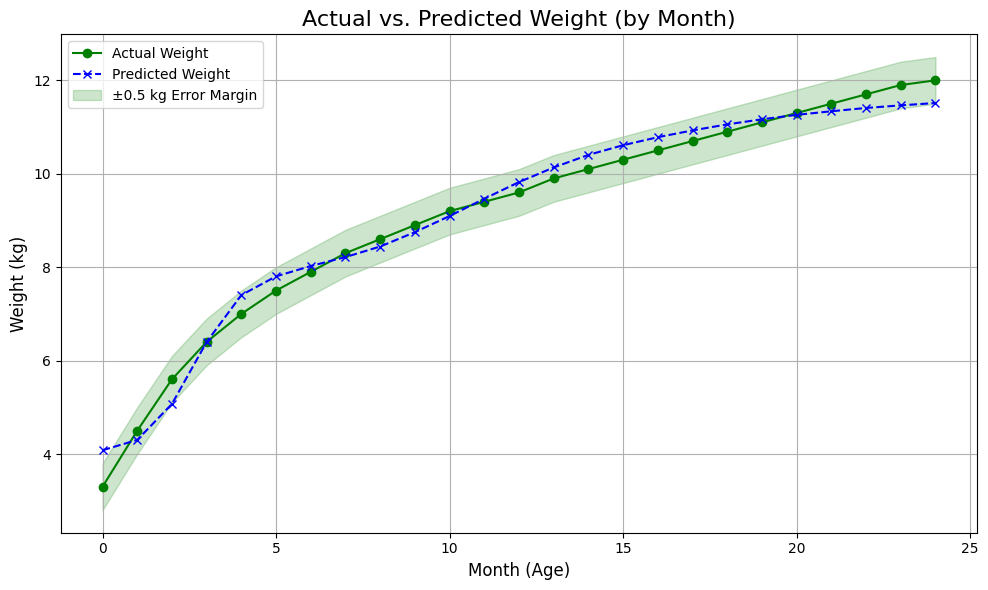

In [840]:
# Convert tensors to NumPy arrays for plotting
targets = targets * std + mean

preds_np = preds.detach().numpy().flatten()
targets_np = targets.detach().numpy().flatten() # Corrected here
months = np.arange(0, 25)

# Create the plot
plt.figure(figsize=(10, 6))

# Plot the actual and predicted weight lines
plt.plot(months, targets_np, marker='o', linestyle='-', color='green', label='Actual Weight')
plt.plot(months, preds_np, marker='x', linestyle='--', color='blue', label='Predicted Weight')

# Add the shaded error area around the actual weight line
plt.fill_between(months, targets_np - 0.5, targets_np + 0.5, color='green', alpha=0.2, label='±0.5 kg Error Margin')

# Add labels and title
plt.title('Actual vs. Predicted Weight (by Month)', fontsize=16)
plt.xlabel('Month (Age)', fontsize=12)
plt.ylabel('Weight (kg)', fontsize=12)
plt.legend(loc='best')
plt.grid(True)
plt.tight_layout()

# Display the plot
plt.show()

# TESTING MODEL

VVV input data below VVV

Predicted weight: 10.96 kg
10.96 Kg → Normal condition (WHO median ~10.50)


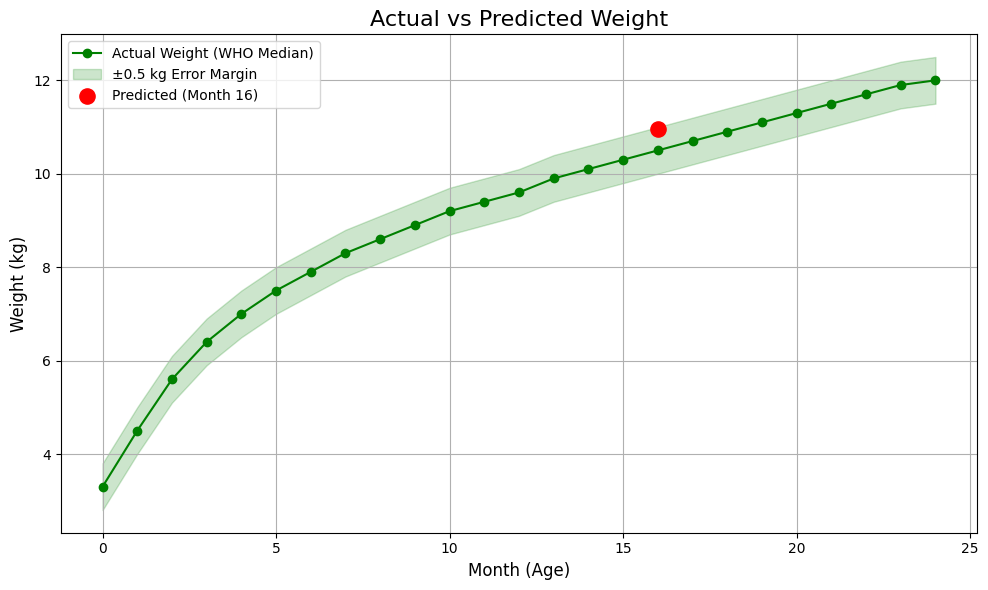

In [884]:
# ----------------------------
# 1. Make Prediction
# ----------------------------
new_data = torch.tensor([[45.2000, 80.3000, 16.0000]], dtype=torch.float32)  # [head, length, month]
# !!!TRY TO EDIT THIS 3 DATA ABOVE!!!


# Predict
pred_norm = model(new_data)
pred_kg = (pred_norm * std + mean).item()  # denormalize weight
print(f"Predicted weight: {pred_kg:.2f} kg")

# Compare with WHO median (at that month)
month = int(new_data[0,2].item())
actual_kg = targets[month].item()  # WHO target already denormalized earlier

if pred_kg > actual_kg + 0.5:
    print(f"{pred_kg:.2f} Kg → Overweight (WHO median ~{actual_kg:.2f})")
elif pred_kg < actual_kg - 0.5:
    print(f"{pred_kg:.2f} Kg → Underweight (WHO median ~{actual_kg:.2f})")
else:
    print(f"{pred_kg:.2f} Kg → Normal condition (WHO median ~{actual_kg:.2f})")


# ----------------------------
# 2. Plot in 2D (Matplotlib)
# ----------------------------
plt.figure(figsize=(10, 6))

# Actual WHO median curve
plt.plot(months, targets_np, marker='o', linestyle='-', color='green', label='Actual Weight (WHO Median)')

# Error margin shading
plt.fill_between(months, targets_np - 0.5, targets_np + 0.5,
                 color='green', alpha=0.2, label='±0.5 kg Error Margin')

# Highlight new point
plt.scatter(new_data[0,2].item(), pred_kg, color='red', s=120,
            label=f'Predicted (Month {month})')

plt.title('Actual vs Predicted Weight', fontsize=16)
plt.xlabel('Month (Age)', fontsize=12)
plt.ylabel('Weight (kg)', fontsize=12)
plt.legend(loc='best')
plt.grid(True)
plt.tight_layout()
plt.show()


# ----------------------------
# 3. Plot in 3D (Plotly interactive)
# ----------------------------
import plotly.graph_objects as go

# Growth line (colored by weight)
trace1 = go.Scatter3d(
    x=months, y=lengths, z=head_circs,
    mode='lines+markers',
    marker=dict(size=5, color=weights.flatten(), colorscale='Viridis',
                colorbar=dict(title='Weight (kg)')),
    line=dict(color='blue', width=4)
)

# Test point
trace2 = go.Scatter3d(
    x=[new_data[0,2].item()],
    y=[new_data[0,1].item()],
    z=[new_data[0,0].item()],
    mode='markers+text',
    marker=dict(size=8, color='red'),
    text=[f"Pred {pred_kg:.2f} kg"],
    textposition="top center"
)

fig = go.Figure(data=[trace1, trace2])
fig.update_layout(
    scene=dict(
        xaxis_title='Month (Age)',
        yaxis_title='Length (cm)',
        zaxis_title='Head Circumference (cm)'
    ),
    title="3D Growth Path (Interactive)"
)

fig.show()
